> **Production run.** Same notebook with the numbers of replicas, toy experiments and chain lengths of the report. Run with `run_full.sh`; expect several hours.

# 07 · Bayesian analysis (3/3): credible against confidence intervals at low statistics

**What this notebook does.** With $\sim2\times10^4$ candidates the posterior is Gaussian and the credible and confidence
intervals coincide. Here we look for the regime in which they differ: the *same* likelihood is analysed both ways on
pseudo-datasets of 50–2000 candidates (minimal six-parameter model), and the asymptotic behaviour of the
maximum-likelihood estimate is measured.

| § | Content | Report section |
|---|---|---|
| 10 | Coverage of Bayesian, Minos and Hesse intervals against $N$; asymptotic behaviour | Discussion (add.: low statistics, asymptotic behavior) |

**Scale.** A guided tour of the method, not the production run: replicas, toy experiments and chains are fewer than in
the report, so numbers can differ slightly from it; next to every result the notebook prints the value of the report
(**report:**). The notebook is self-contained and saves its figures in `figures/` and its numbers in `results/`.
Parts beyond the techniques of the course are tagged **[EXTRA]**.

## 0 · Common setup (data, model and Bayesian fit tools, as in notebooks 05 and 06)

## 0 · Setup

In [1]:
import os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot, emcee, corner
from scipy.special import ndtr
from scipy.stats import norm, chi2, crystalball, gaussian_kde
from iminuit import Minuit

import plot_style
plot_style.use()
C = plot_style.COLORS
T0 = time.time()
np.random.seed(42)

# figures and numerical results are saved next to the notebook
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
def save_fig(name):
    """Save the current figure in figures/ and show it."""
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

DATA_DIR = "data" if os.path.isdir("data") else "../../opendata-project/Data"
M_K = 493.677
LO, HI = 5100.0, 5600.0

## 1 · Data, prior, likelihood and posterior

### 1.1 Data
Same preselection and window as in notebook 01 (all three tracks kaon-like and not muons), here in compact form.
We keep the candidates with the weaker PID cut of the variants ($\texttt{ProbK}>0.4$, $\texttt{ProbPi}<0.6$) and
store the weakest PID value of each candidate, so that variants only re-apply tighter cuts.

In [2]:
tracks = (1, 2, 3)                          # the three final-state hadrons
branches = [f"H{i}_{v}" for i in tracks for v in ("PX", "PY", "PZ", "ProbK", "ProbPi", "isMuon", "Charge")]
frames = []
for pol in ("Down", "Up"):                  # one file per magnet polarity
    with uproot.open(f"{DATA_DIR}/B2HHH_Magnet{pol}.root") as f:
        t = f["DecayTree"].arrays(branches, library="pd")
    t["magnet"] = pol.lower()
    frames.append(t)
df = pd.concat(frames, ignore_index=True)

# loose preselection (looser than every variant of the systematic study): kaon-like and not muon on all three tracks
keep = np.ones(len(df), bool)
for i in tracks:
    keep &= ((df[f"H{i}_ProbK"] > 0.4) & (df[f"H{i}_ProbPi"] < 0.6) & ~df[f"H{i}_isMuon"].astype(bool)).to_numpy()
d = df[keep].reset_index(drop=True); del df

def invariant_mass(d, particles):
    """Invariant mass [MeV] of the listed tracks with the kaon-mass hypothesis: m^2 = E^2 - |p|^2."""
    E = sum(np.sqrt(d[f"H{i}_PX"]**2 + d[f"H{i}_PY"]**2 + d[f"H{i}_PZ"]**2 + M_K**2) for i in particles)
    px, py, pz = (sum(d[f"H{i}_{c}"] for i in particles) for c in ("PX", "PY", "PZ"))
    return np.sqrt(np.clip(E**2 - px**2 - py**2 - pz**2, 0, None))

d["m"], d["m12"], d["m13"] = invariant_mass(d, (1, 2, 3)), invariant_mass(d, (1, 2)), invariant_mass(d, (1, 3))
d["q"] = d.H1_Charge + d.H2_Charge + d.H3_Charge                      # charge of the B
d["min_probk"] = d[[f"H{i}_ProbK" for i in tracks]].min(axis=1)       # weakest kaon likelihood of the candidate
d["max_probpi"] = d[[f"H{i}_ProbPi" for i in tracks]].max(axis=1)     # largest pion likelihood of the candidate
d = d[np.abs(d.q) == 1]

def select(lo=LO, hi=HI, k=0.5, pi=0.5, s=None):
    """Candidates with mass in (lo, hi), min ProbK > k and max ProbPi < pi (nominal: 0.5, 0.5)."""
    s = d if s is None else s
    return s[(s.m > lo) & (s.m < hi) & (s.min_probk > k) & (s.max_probpi < pi)].reset_index(drop=True)

sample = select()                                                     # nominal sample
m_pos, m_neg = sample.m[sample.q > 0].to_numpy(), sample.m[sample.q < 0].to_numpy()
print(f"candidates in the window: {len(sample)} (report 19731);  B+: {len(m_pos)}, B-: {len(m_neg)}")

candidates in the window: 19731 (report 19731);  B+: 10292, B-: 9439


### 1.2 The model, written as log-prior, log-likelihood and log-posterior

The model is that of notebook 01: for each charge a Gaussian signal (mean $\mu$ and width $\sigma$ shared) and a
double-exponential background (own shape and yield), $N_s^\pm=\frac{N_s}{2}(1\mp A)$,
$N_b^\pm=\frac{N_b}{2}(1\mp A_b)$. Twelve parameters
$\theta=(N_s,N_b,A,A_b,\mu,\sigma,\lambda_1^\pm,\lambda_2^\pm,f_\pm)$.

* **Prior** $\pi(\theta)$: independent and **uniform** on the ranges below (constant in the allowed region, zero
  outside); $\lambda_1>\lambda_2$ removes the label-switching symmetry of the two exponentials. With flat priors the
  posterior is proportional to the likelihood inside the allowed region.
* **Likelihood**: the extended unbinned likelihood of notebook 01.
* **Posterior**: $\ln p(\theta|D)=\ln\mathcal L(D|\theta)+\ln\pi(\theta)$ + const. The evidence $p(D)$ is a constant
  that the MCMC does not need.

In [3]:
# the 12 parameters, in the order of the vector theta used by the sampler
names = ["N_s", "N_b", "A", "A_b", "mu", "sigma", "lam1_pos", "lam2_pos", "f_pos", "lam1_neg", "lam2_neg", "f_neg"]
N = len(sample)
# uniform prior = allowed range of each parameter (zero probability outside)
PRIOR = {"N_s": (0, 5 * N), "N_b": (0, 5 * N), "A": (-1, 1), "A_b": (-1, 1), "mu": (5260, 5310), "sigma": (3, 40),
         "lam1_pos": (1e-5, 0.1), "lam2_pos": (1e-5, 0.1), "f_pos": (0, 1),
         "lam1_neg": (1e-5, 0.1), "lam2_neg": (1e-5, 0.1), "f_neg": (0, 1)}

# building blocks of the model, as in notebook 01
def gauss_pdf(m, mu, sigma, lo=LO, hi=HI):
    """Gaussian normalised on [lo, hi]: written with ndtr (the normal cdf) because it is faster than scipy.stats."""
    z = (m - mu) / sigma
    return np.exp(-0.5 * z * z) / (sigma * np.sqrt(2 * np.pi)) / (ndtr((hi - mu) / sigma) - ndtr((lo - mu) / sigma))

def exp_pdf(m, lam, lo=LO, hi=HI):
    """Exponential exp(-lam (m - lo)) normalised on [lo, hi]."""
    return lam * np.exp(-lam * (m - lo)) / (1 - np.exp(-lam * (hi - lo)))

def bkg_pdf(m, lam1, lam2, f, lo=LO, hi=HI):
    """Background: weight f on the steep exponential (lam1 > lam2), 1 - f on the slow one."""
    return f * exp_pdf(m, lam1, lo, hi) + (1 - f) * exp_pdf(m, lam2, lo, hi)

def log_prior(theta):
    """ln of the prior: 0 inside the allowed region (uniform, an irrelevant constant), -inf outside."""
    v = dict(zip(names, theta))
    for k in names:
        if not PRIOR[k][0] < v[k] < PRIOR[k][1]:
            return -np.inf
    if v["lam1_pos"] <= v["lam2_pos"] or v["lam1_neg"] <= v["lam2_neg"]:      # ordering of the two exponentials
        return -np.inf                                                       # (removes the label-switching symmetry)
    return 0.0

def log_likelihood(theta, m_p, m_n):
    """ln of the extended unbinned likelihood of the B+ masses m_p and B- masses m_n."""
    v = dict(zip(names, theta))
    Ns_p, Ns_n = v["N_s"] * (1 - v["A"]) / 2, v["N_s"] * (1 + v["A"]) / 2          # signal yields per charge
    Nb_p, Nb_n = v["N_b"] * (1 - v["A_b"]) / 2, v["N_b"] * (1 + v["A_b"]) / 2      # background yields per charge
    dens_p = Ns_p * gauss_pdf(m_p, v["mu"], v["sigma"]) + Nb_p * bkg_pdf(m_p, v["lam1_pos"], v["lam2_pos"], v["f_pos"])
    dens_n = Ns_n * gauss_pdf(m_n, v["mu"], v["sigma"]) + Nb_n * bkg_pdf(m_n, v["lam1_neg"], v["lam2_neg"], v["f_neg"])
    return np.sum(np.log(dens_p)) + np.sum(np.log(dens_n)) - (v["N_s"] + v["N_b"])    # extended: -(N_s + N_b)

def log_posterior(theta, m_p=m_pos, m_n=m_neg):
    """ln posterior = ln prior + ln likelihood (up to a constant: the evidence)."""
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    ll = log_likelihood(theta, m_p, m_n)
    return lp + ll if np.isfinite(ll) else -np.inf

### 1.3 Starting point: the maximum of the posterior

With flat priors the maximum of the posterior (MAP) is the maximum-likelihood estimate: we find it with `Migrad`
and use it to start the walkers close to the bulk.

In [4]:
# rough starting values
theta0 = dict(N_s=0.78 * N, N_b=0.22 * N, A=-0.04, A_b=0.0, mu=5284.0, sigma=18.0,
              lam1_pos=0.03, lam2_pos=0.002, f_pos=0.15, lam1_neg=0.03, lam2_neg=0.002, f_neg=0.15)

def neg2logp(*theta):
    """-2 ln posterior, the function that Migrad minimises (a large number outside the prior)."""
    lp = log_posterior(np.array(theta))
    return -2 * lp if np.isfinite(lp) else 1e10

mmap = Minuit(neg2logp, *[theta0[k] for k in names], name=names)
for k in names:
    mmap.limits[k] = PRIOR[k]               # the prior ranges are the limits of the minimisation
mmap.migrad()
theta_map = np.array(mmap.values)           # maximum of the posterior (= maximum likelihood with flat priors)
print(f"MAP: A = {mmap.values['A']:+.4f},  N_s = {mmap.values['N_s']:.0f},  mu = {mmap.values['mu']:.2f},  "
      f"sigma = {mmap.values['sigma']:.2f}   (valid: {mmap.valid})")
# cost of one evaluation: sets the cost of the MCMC (walkers x steps evaluations)
t0 = time.time(); [log_posterior(theta_map) for _ in range(200)]
print(f"time per log-posterior call: {(time.time() - t0) / 200 * 1e3:.2f} ms")

MAP: A = -0.0441,  N_s = 15328,  mu = 5284.38,  sigma = 18.00   (valid: True)
time per log-posterior call: 0.54 ms


In [5]:
from scipy.stats import crystalball

def cb_pdf(m, mu, sigma, beta, m_cb, lo=LO, hi=HI):
    """Crystal Ball (Gaussian core with a power-law low-mass tail) normalised on [lo, hi]."""
    z = crystalball.cdf((hi - mu) / sigma, beta, m_cb) - crystalball.cdf((lo - mu) / sigma, beta, m_cb)
    return crystalball.pdf((m - mu) / sigma, beta, m_cb) / sigma / z

def density(v, side, m, lo=LO, hi=HI, cb=False):
    """Expected density of the events of one charge. v is a dictionary with ALL the parameters of the model."""
    sign = -1 if side == "pos" else +1
    n_sig = v["N_s"] * (1 + sign * v["A"]) / 2
    n_bkg = v["N_b"] * (1 + sign * v["A_b"]) / 2
    mu = v.get(f"mu_{side}", v.get("mu"))                  # mu and sigma: own for each charge, or common
    sigma = v.get(f"sigma_{side}", v.get("sigma"))
    sig = cb_pdf(m, mu, sigma, v["beta"], v["m_cb"], lo, hi) if cb else gauss_pdf(m, mu, sigma, lo, hi)
    bkg = bkg_pdf(m, v[f"lam1_{side}"], v[f"lam2_{side}"], v[f"f_{side}"], lo, hi)
    return n_sig * sig + n_bkg * bkg

# the functions that complete the dictionary of a variant with its tied or fixed parameters
def nothing(v):
    pass
def tie_shapes(v):              # background shape of B- equal to that of B+
    v["lam1_neg"], v["lam2_neg"], v["f_neg"] = v["lam1_pos"], v["lam2_pos"], v["f_pos"]
def zero_Ab(v):                 # charge-symmetric background
    v["A_b"] = 0.0
def one_exponential(v):         # a single exponential: all the weight on the first one
    v["f_pos"] = v["f_neg"] = 1.0
    v["lam2_pos"] = v["lam2_neg"] = 1e-4

def without(all_names, drop):
    return [n for n in all_names if n not in drop]

# a variant = names of the SAMPLED parameters + function that completes the others + window + signal shape
NOM = dict(names=names, fill=nothing, lo=LO, hi=HI, cb=False, start={})          # the nominal model of section 1

def make_prior(n_cand, a_bound=1.0):
    """Uniform priors: allowed range of every parameter that any variant can have."""
    return {"N_s": (0, 5 * n_cand), "N_b": (0, 5 * n_cand), "A": (-a_bound, a_bound), "A_b": (-1, 1),
            "mu": (5260, 5310), "sigma": (3, 40), "mu_pos": (5260, 5310), "mu_neg": (5260, 5310),
            "sigma_pos": (3, 40), "sigma_neg": (3, 40), "beta": (0.3, 5), "m_cb": (1.01, 50),
            "lam1_pos": (1e-5, 0.1), "lam2_pos": (1e-5, 0.1), "f_pos": (0, 1),
            "lam1_neg": (1e-5, 0.1), "lam2_neg": (1e-5, 0.1), "f_neg": (0, 1)}

def log_posterior_variant(theta, spec, prior, m_p, m_n):
    """ln posterior of a variant (uniform priors, extended likelihood), at the vector theta of its sampled parameters."""
    v = dict(zip(spec["names"], theta))
    for k in spec["names"]:                                # uniform prior: inside the allowed range or zero
        if not prior[k][0] < v[k] < prior[k][1]:
            return -np.inf
    spec["fill"](v)                                        # tied and fixed parameters
    if "lam2_pos" in spec["names"] and (v["lam1_pos"] <= v["lam2_pos"] or v["lam1_neg"] <= v["lam2_neg"]):
        return -np.inf                                     # ordering of the two exponentials
    dp = density(v, "pos", m_p, spec["lo"], spec["hi"], spec["cb"])
    dn = density(v, "neg", m_n, spec["lo"], spec["hi"], spec["cb"])
    if np.any(dp <= 0) or np.any(dn <= 0):
        return -np.inf
    return np.sum(np.log(dp)) + np.sum(np.log(dn)) - (v["N_s"] + v["N_b"])      # extended likelihood

# check: the nominal variant is exactly the posterior of section 1
assert abs(log_posterior_variant(theta_map, NOM, make_prior(len(sample)), m_pos, m_neg) - log_posterior(theta_map)) < 1e-6
print("nominal variant = posterior of section 1: OK")

nominal variant = posterior of section 1: OK


In [6]:
def fit_map(s, spec=NOM, a_bound=1.0, start_from=None):
    """Maximum of the posterior of a variant (Migrad). Returns the Minuit object and the log-posterior function."""
    mp, mn = s.m[s.q > 0].to_numpy(), s.m[s.q < 0].to_numpy()
    prior = make_prior(len(s), a_bound)
    lp = lambda theta: log_posterior_variant(theta, spec, prior, mp, mn)
    start = {"N_s": 0.78 * len(s), "N_b": 0.22 * len(s), "A": -0.04, "A_b": 0.0, "mu": 5284.0, "sigma": 18.0,
             "mu_pos": 5284.0, "mu_neg": 5284.0, "sigma_pos": 18.0, "sigma_neg": 18.0, "beta": 1.8, "m_cb": 10.0,
             "lam1_pos": 0.03, "lam1_neg": 0.03, "lam2_pos": 0.002, "lam2_neg": 0.002, "f_pos": 0.15, "f_neg": 0.15}
    start.update(spec["start"]); start.update(start_from or {})
    def f(*theta):                                         # -2 ln posterior for Migrad
        v = lp(np.array(theta))
        return -2 * v if np.isfinite(v) else 1e10
    mm = Minuit(f, *[start[k] for k in spec["names"]], name=spec["names"])
    for k in spec["names"]:
        mm.limits[k] = prior[k]
    mm.migrad()
    return mm, lp

def bayes_fit(s, spec=NOM, nsteps=1500, burn=300, nwalkers=None, a_bound=1.0, start_from=None):
    """Posterior of a variant: maximum of the posterior (start of the walkers), then emcee.
    s is a DataFrame with columns m and q; spec describes the variant."""
    mm, lp = fit_map(s, spec, a_bound, start_from)
    nm = spec["names"]
    x_map = np.array(mm.values)
    nw = nwalkers or max(2 * len(nm) + 2, 24)                 # emcee needs at least 2 x parameters walkers
    p0 = x_map + 1e-3 * np.abs(x_map) * np.random.randn(nw, len(nm))      # small ball around the maximum
    for k in ("A", "A_b"):                                    # A, A_b are close to zero: absolute spread
        if k in nm: p0[:, nm.index(k)] = x_map[nm.index(k)] + 1e-3 * np.random.randn(nw)
    for w in range(nw):                                       # every walker must start inside the prior
        while not np.isfinite(lp(p0[w])):
            p0[w] = x_map + 1e-4 * np.abs(x_map) * np.random.randn(len(nm))
    samp = emcee.EnsembleSampler(nw, len(nm), lp)
    samp.run_mcmc(p0, nsteps, progress=False)
    ch = samp.get_chain(discard=burn, flat=True)              # drop the burn-in, merge the walkers

    def expected(v, side, m):                                 # expected density at the parameters v (a dictionary)
        full = dict(v); spec["fill"](full)
        return density(full, side, m, spec["lo"], spec["hi"], spec["cb"])
    return dict(names=nm, chain=ch, map=x_map, logpost=lp, density=expected, minuit=mm,
                A=np.median(ch[:, nm.index("A")]), sd=ch[:, nm.index("A")].std(),
                ci68=np.percentile(ch[:, nm.index("A")], [15.865, 84.135]), n=len(s))

def binned_chi2_bayes(res, s, lo=LO, hi=HI, width=10.0):
    """Pearson chi2 (10 MeV bins, both charges) at the posterior median of the parameters."""
    v = dict(zip(res["names"], np.median(res["chain"], axis=0)))
    edges = np.arange(lo, hi + 1e-9, width)
    sub = (np.arange(5) + 0.5) / 5                            # 5 points per bin to average the density
    pts = edges[:-1, None] + sub[None, :] * width
    chi2_ = 0.0
    for side, mask in (("pos", s.q > 0), ("neg", s.q < 0)):
        nu = res["density"](v, side, pts).mean(axis=1) * width          # expected counts per bin
        obs = np.histogram(s.m[mask], edges)[0]                         # observed counts per bin
        chi2_ += np.sum((obs - nu)**2 / nu)
    return chi2_

## 10 · Low statistics: where do credible and confidence intervals differ?

We use a **minimal model** of six parameters on $[5150,5450]$ MeV: Gaussian signal, *one* exponential background with
shape and yield shared by the two charges, $A_b=0$ (the nominal model is not identifiable with 50 events).

* **Bayesian**: `emcee`, flat priors, median and equal-tailed 68 %/95 % credible interval.
* **Frequentist**: `Migrad` on the same function, Hesse ($\pm\sigma$) and Minos (profile likelihood) intervals.

*Report:* 300 toys per size, 4000 steps. Here fewer (see the cells).

minimal model on the data: n = 17839,  A = -0.0494  68% CI [-0.0579, -0.0410]     (report: -0.0497, [-0.058, -0.041])


1799 toys in 8259 s (1 excluded: Migrad minimum not valid)
      cov68 Bayes  cov68 Minos  cov68 Hesse  cov95 Bayes  cov95 Hesse  bias median  bias MLE
N                                                                                           
50          0.690        0.679        0.670        0.955        0.931        0.001    -0.000
150         0.678        0.678        0.676        0.960        0.953       -0.002    -0.002
500         0.622        0.624        0.622        0.936        0.933        0.004     0.004
2000        0.658        0.658        0.658        0.924        0.929       -0.001    -0.001


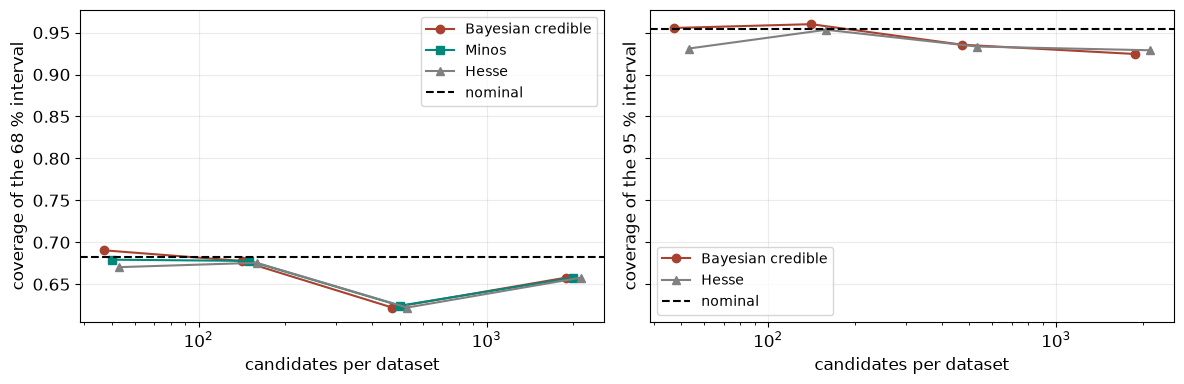

with 15 toys per size the binomial uncertainty of each 68% coverage is ~0.10 (0.03 with the 300 toys of the report);
report: coverage of the three intervals consistent with nominal from 2000 down to 50 candidates; the median and the MLE differ only at the smallest sizes


In [7]:
def minimal_fill(v):            # six-parameter model: one exponential, same shape and yield for the two charges, A_b = 0
    v["A_b"] = 0.0
    v["lam1_neg"] = v["lam1_pos"]
    v["lam2_pos"] = v["lam2_neg"] = 1e-4
    v["f_pos"] = v["f_neg"] = 1.0
MIN_SPEC = {**NOM, "names": ["N_s", "N_b", "A", "mu", "sigma", "lam1_pos"], "fill": minimal_fill,
            "lo": 5150.0, "hi": 5450.0, "start": {"lam1_pos": 0.004}}
s_min = select(lo=5150.0, hi=5450.0)
r_min = bayes_fit(s_min, MIN_SPEC, nsteps=10000, burn=2000)               # the minimal model on the data
print(f"minimal model on the data: n = {len(s_min)},  A = {r_min['A']:+.4f}  68% CI [{r_min['ci68'][0]:+.4f}, {r_min['ci68'][1]:+.4f}]"
      f"     (report: -0.0497, [-0.058, -0.041])")
v_min = dict(zip(r_min["names"], r_min["map"]))                      # its best-fit parameters: the truth of the toys

def toy_minimal(n_total):
    """Pseudo-dataset from the minimal model with the yields rescaled to n_total candidates."""
    scale = n_total / (v_min["N_s"] + v_min["N_b"])
    out = []
    for sign in (-1, +1):
        n_s = np.random.poisson(v_min["N_s"] * scale * (1 + sign * v_min["A"]) / 2)      # Poisson signal yield
        n_b = np.random.poisson(v_min["N_b"] * scale / 2)                                # and background yield
        u = np.random.uniform(norm.cdf(5150, v_min["mu"], v_min["sigma"]), norm.cdf(5450, v_min["mu"], v_min["sigma"]), n_s)
        sig = v_min["mu"] + v_min["sigma"] * norm.ppf(u)                                 # truncated Gaussian by inversion
        # exponential by inversion of its cdf on the window [5150, 5450] (width 300 MeV)
        bkg = 5150 - np.log(1 - np.random.uniform(size=n_b) * (1 - np.exp(-v_min["lam1_pos"] * 300))) / v_min["lam1_pos"]
        out.append(np.concatenate([sig, bkg]))
    return out

a_min = v_min["A"]
cov_rows = []
n_invalid = 0
t0 = time.time()
for n_total in (50, 150, 500, 2000):                                  # number of candidates per pseudo-dataset
    for i in range(450):
        mp_t, mn_t = toy_minimal(n_total)
        toy = pd.DataFrame({"m": np.concatenate([mp_t, mn_t]), "q": np.concatenate([np.ones(len(mp_t)), -np.ones(len(mn_t))])})
        if min(len(mp_t), len(mn_t)) < 2:
            continue
        r = bayes_fit(toy, MIN_SPEC, nsteps=4000, burn=1000, nwalkers=16, start_from=v_min)       # Bayesian: posterior
        ch = r["chain"][:, r["names"].index("A")]
        m_ = r["minuit"]                                                                    # frequentist: same function, Migrad
        try:
            m_.hesse(); m_.minos("A")
        except RuntimeError:                                                                # invalid minimum (not converged):
            n_invalid += 1                                                                  # the toy is excluded, as in notebook 02
            continue
        a_hat, da = m_.values["A"], m_.errors["A"]
        lo_m, hi_m = a_hat + m_.merrors["A"].lower, a_hat + m_.merrors["A"].upper           # Minos (profile likelihood) interval
        cov_rows.append(dict(N=n_total,                                                     # does each interval contain the truth?
                             bayes68=np.percentile(ch, 15.865) < a_min < np.percentile(ch, 84.135),
                             bayes95=np.percentile(ch, 2.5) < a_min < np.percentile(ch, 97.5),
                             minos68=lo_m < a_min < hi_m,
                             hesse68=abs(a_hat - a_min) < da, hesse95=abs(a_hat - a_min) < 1.96 * da,
                             median=np.median(ch), mle=a_hat))
print(f"{len(cov_rows)} toys in {time.time() - t0:.0f} s ({n_invalid} excluded: Migrad minimum not valid)")
cov = pd.DataFrame(cov_rows).groupby("N").agg({"bayes68": "mean", "minos68": "mean", "hesse68": "mean", "bayes95": "mean", "hesse95": "mean",
                                               "median": lambda x: x.mean() - a_min, "mle": lambda x: x.mean() - a_min})
cov.columns = ["cov68 Bayes", "cov68 Minos", "cov68 Hesse", "cov95 Bayes", "cov95 Hesse", "bias median", "bias MLE"]
print(cov.round(3).to_string())
# coverage of the three intervals against the number of candidates
sizes = cov.index.to_numpy()
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, (lvl, nomv, cols) in zip(ax, (("68", 0.6827, ("cov68 Bayes", "cov68 Minos", "cov68 Hesse")),
                                     ("95", 0.9545, ("cov95 Bayes", None, "cov95 Hesse")))):
    for k_, (c_, lab, col_, mk) in enumerate(zip(cols, ("Bayesian credible", "Minos", "Hesse"), (C["bayes"], C["freq"], "gray"), "os^")):
        if c_ is not None:
            a.plot(sizes * (1 + 0.06 * (k_ - 1)), cov[c_], mk + "-", color=col_, label=lab)
    a.axhline(nomv, color="k", ls="--", label="nominal"); a.set(xscale="log", xlabel="candidates per dataset", ylabel=f"coverage of the {lvl} % interval"); a.legend()
plt.tight_layout(); save_fig("07_coverage_vs_N")
print("with 15 toys per size the binomial uncertainty of each 68% coverage is ~0.10 (0.03 with the 300 toys of the report);")
print("report: coverage of the three intervals consistent with nominal from 2000 down to 50 candidates; "
      "the median and the MLE differ only at the smallest sizes")

**Asymptotic behaviour of the estimator.** With more candidates the maximum-likelihood estimate of $A$ should become
unbiased, Gaussian, with $\sigma\propto1/\sqrt N$. With the same minimal model we fit many toy datasets by
maximum likelihood only (cheap, no MCMC) and look at bias, spread, skewness, excess kurtosis and the Shapiro–Wilk test
of normality. *Report:* 300 toys per size. Here 60.

    N    n     bias       sd sd*sqrt(N) lin. prop.   skew ex.kurt.  Shapiro p


   50  900  +0.0076   0.1550      1.096     0.1526  -0.01    +0.08      0.250


  150  900  -0.0002   0.0875      1.072     0.0881  +0.12    +0.39      0.019


  500  900  -0.0004   0.0500      1.119     0.0483  +0.01    -0.23      0.370


 2000  900  -0.0006   0.0251      1.122     0.0241  -0.11    +0.05      0.392


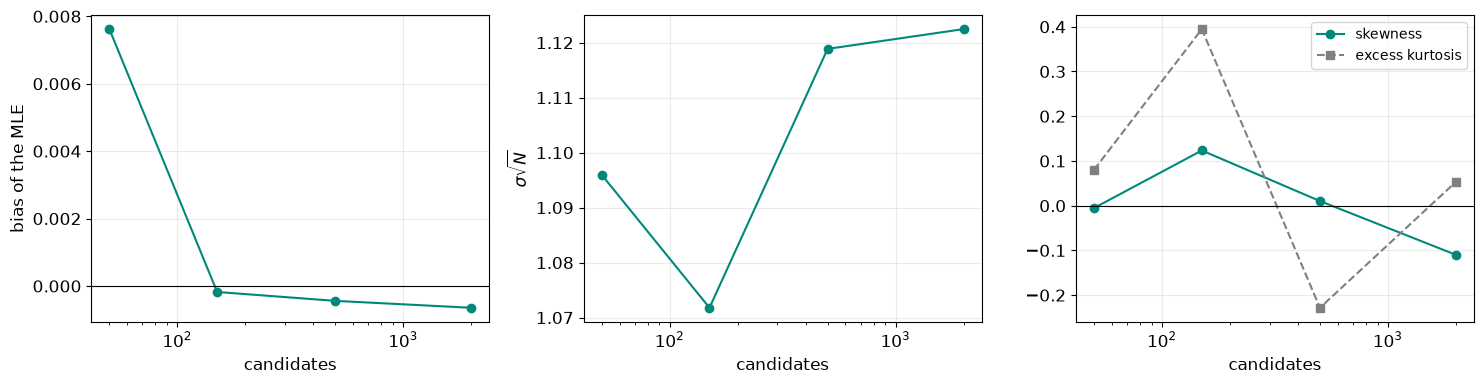

report: bias -> 0, sd scales as N^-1/2 (sd*sqrt(N) constant), skewness and excess kurtosis -> 0 as N grows


In [8]:
from scipy import stats as sps

def mle_minimal(mp, mn):
    """Maximum-likelihood estimate of A in the minimal model (Migrad on -2 ln posterior, flat priors)."""
    toy = pd.DataFrame({"m": np.concatenate([mp, mn]), "q": np.concatenate([np.ones(len(mp)), -np.ones(len(mn))])})
    mm, _ = fit_map(toy, MIN_SPEC, start_from=v_min)
    return mm.values["A"], mm.valid

f_sig = v_min["N_s"] / (v_min["N_s"] + v_min["N_b"])               # signal fraction (for the linear error propagation)
print(f"{'N':>5s} {'n':>4s} {'bias':>8s} {'sd':>8s} {'sd*sqrt(N)':>10s} {'lin. prop.':>10s} {'skew':>6s} {'ex.kurt.':>8s} {'Shapiro p':>10s}")
asym_rows = []
for n_total in (50, 150, 500, 2000):
    est = []
    for _ in range(900):
        mp_t, mn_t = toy_minimal(n_total)
        if min(len(mp_t), len(mn_t)) > 2:
            a_, ok_ = mle_minimal(mp_t, mn_t)
            if ok_: est.append(a_)
    est = np.array(est)                                               # estimates over the toys of this size
    asym_rows.append(dict(N=n_total, n=len(est), bias=est.mean() - a_min, sd=est.std(), sd_sqrtN=est.std() * np.sqrt(n_total),
                          linear_propagation=np.sqrt((1 - a_min**2) / (f_sig * n_total)), skewness=sps.skew(est),
                          excess_kurtosis=sps.kurtosis(est), shapiro_p=sps.shapiro(est).pvalue))
    r_ = asym_rows[-1]
    print(f"{n_total:5d} {len(est):4d} {r_['bias']:+8.4f} {r_['sd']:8.4f} {r_['sd_sqrtN']:10.3f} "
          f"{r_['linear_propagation']:10.4f} {r_['skewness']:+6.2f} {r_['excess_kurtosis']:+8.2f} {r_['shapiro_p']:10.3f}")
asym = pd.DataFrame(asym_rows)
asym.to_csv("results/07_asymptotic_behaviour.csv", index=False)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(asym.N, asym.bias, "o-", color=C["freq"]); ax[0].axhline(0, color="k", lw=0.8); ax[0].set(xscale="log", xlabel="candidates", ylabel="bias of the MLE")
ax[1].plot(asym.N, asym.sd_sqrtN, "o-", color=C["freq"]); ax[1].set(xscale="log", xlabel="candidates", ylabel="$\\sigma\\sqrt{N}$")
ax[2].plot(asym.N, asym.skewness, "o-", color=C["freq"], label="skewness"); ax[2].plot(asym.N, asym.excess_kurtosis, "s--", color="gray", label="excess kurtosis")
ax[2].axhline(0, color="k", lw=0.8); ax[2].set(xscale="log", xlabel="candidates"); ax[2].legend()
plt.tight_layout(); save_fig("07_asymptotic_behaviour")
print("report: bias -> 0, sd scales as N^-1/2 (sd*sqrt(N) constant), skewness and excess kurtosis -> 0 as N grows")

**Reading the result.** As the number of candidates grows the bias goes to zero, $\sigma\sqrt N$ becomes constant (the uncertainty scales as $N^{-1/2}$) and skewness and excess kurtosis go to zero: the estimator reaches its asymptotic regime, where Wilks' theorem and the Gaussian approximation of the posterior hold.

## Results saved

In [9]:
summary = dict(minimal_model_on_data=dict(A=float(r_min["A"]), ci68=[float(x) for x in r_min["ci68"]], n=int(len(s_min))))
json.dump(summary, open("results/07_summary.json", "w"), indent=1)
cov.to_csv("results/07_low_statistics_coverage.csv")
print("saved results/07_summary.json and the coverage table")

saved results/07_summary.json and the coverage table


## Summary
* Credible, Minos and Hesse intervals of the same likelihood have **compatible coverage** from $2000$ down to $50$
  candidates, and the median and the maximum-likelihood estimate differ only at the smallest sizes.
* The estimator becomes unbiased and Gaussian with $\sigma\propto1/\sqrt N$ as $N$ grows (skewness and kurtosis
  tend to zero).

In [10]:
print(f"Running time of this notebook: {(time.time() - T0) / 60:.1f} min")

Running time of this notebook: 140.9 min
